In [1]:
import pickle
import json
import os
import matplotlib.pyplot as plt
import numpy as np
from enum import Enum
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
import cv2
from tqdm import tqdm


import librosa
import IPython.display as ipd

import pyroomacoustics as pra
from scipy.spatial.transform import Rotation as R


import dynamic_sound as ds
from airsim.data_converter import data_converter, perspective_to_equirectangular

class Data(Enum):
    TIMESTAMP = 1
    DRONE_POSITION = 2 # will collect the drone's current position [x, y, z] at each frame
    DRONE_ROTATION = 3
    DRONE_VELOCITY = 4 # will collect the drone's current velocity [vx, vy, vz] at each frame
    CAMERA_POSITION = 5
    CAMERA_ROTATION = 6
    BGR = 7 # will collect BGR (not RGB) images from the scene at each frame
    ROTOR_SPEED = 8

SMALL_SIZE = 18
MEDIUM_SIZE = 22
BIGGER_SIZE = 26

plt.rc('font', size=SMALL_SIZE)          # controls default text sizes
plt.rc('axes', titlesize=SMALL_SIZE)     # fontsize of the axes title
plt.rc('axes', labelsize=MEDIUM_SIZE)    # fontsize of the x and y labels
plt.rc('xtick', labelsize=SMALL_SIZE)    # fontsize of the tick labels
plt.rc('ytick', labelsize=SMALL_SIZE)    # fontsize of the tick labels
plt.rc('legend', fontsize=SMALL_SIZE)    # legend fontsize
plt.rc('figure', titlesize=BIGGER_SIZE)  # fontsize of the figure title

## Perspective to Equirectangular projection mapping

In [2]:
os.makedirs("_tmp", exist_ok=True)

data_dir = './airsim/data/run1/'
framerate = 5

data_converter(data_dir, "resources/paths")

frames_path = os.path.join(data_dir, 'frames.p')
params_path = os.path.join(data_dir, 'params.json')
settings_path = os.path.join(data_dir, 'settings.json')

frames = pickle.load(open(frames_path, 'rb'))
params = json.load(open(params_path, 'r'))
settings = json.load(open(settings_path, 'r'))

# helper functions
def bgr_rgb(bgr):
    b = bgr[:, :, 0].copy()
    g = bgr[:, :, 1].copy()
    r = bgr[:, :, 2].copy()
    rgb = np.stack([r, g, b], axis=2)
    return rgb

images_rgb = []
for frame_idx, frame in enumerate(frames):
    if Data.BGR.name in frame:
        bgr = frame[Data.BGR.name]
        rgb = bgr_rgb(bgr)
        images_rgb.append(rgb)

width = settings['ExternalCameras']['FixedCamera']['CaptureSettings'][0]['Width']
height = settings['ExternalCameras']['FixedCamera']['CaptureSettings'][0]['Height']
h_fov = settings['ExternalCameras']['FixedCamera']['CaptureSettings'][0]['FOV_Degrees']
v_fov = 2*np.arctan(np.tan(np.radians(h_fov/2)) * height/width) * 180/np.pi
pitch_deg = settings['ExternalCameras']['FixedCamera']['Pitch']
print(f"width: {width}\n"
      f"height: {height}\n"
      f"h_fov: {h_fov}\n"
      f"v_fov: {int(v_fov)}\n"
      f"pitch: {pitch_deg}")

extent_min_az = h_fov//2
extent_max_az = -h_fov//2
extent_min_el = 90-(-v_fov//2+pitch_deg)
extent_max_el = 90-(v_fov//2+pitch_deg)



frames = np.array(images_rgb)
polar_images = np.empty_like(frames)

for i in range(frames.shape[0]):
    polar_images[i], invalid = perspective_to_equirectangular(
        frames[i],
        src_w=820,
        src_h=400,
        out_w=820,
        out_h=400,
        hfov_deg=128.0,
        vfov_deg=90.0,
        pitch_deg=45.0)
print(f"valid pixels: {(1-invalid.mean())*100:.2f}%")

src_folder = os.path.join("resources", "paths")
drone_path = ds.Path(file=os.path.join(src_folder, "drone_path.csv"))
microphone_path = ds.Path(file=os.path.join(src_folder, "camera_path.csv"))
microphone_path.positions[:, 4] = 1.0   # qw
microphone_path.positions[:, 5:] = 0.0  # qx, qy, qz reset rotation of the microphone array
real_positions = []
mic_sample_rate = 8_000

for image_frame in range(frames.shape[0]):
    start_sample = int(image_frame / framerate * mic_sample_rate)

    # Get the real position of the source relative to the microphone
    real_position_microphone, real_rotation_microphone = microphone_path.get_position(start_sample/mic_sample_rate)
    real_position_source, _ = drone_path.get_position(start_sample/mic_sample_rate)

    if real_position_microphone is None or real_position_source is None:
        continue

    relative_position_azimuth = np.rad2deg(np.arctan2(real_position_source[1] - real_position_microphone[1], real_position_source[0] - real_position_microphone[0]))
    relative_position_colatitude = np.rad2deg(np.arccos((real_position_source[2] - real_position_microphone[2]) / np.linalg.norm(real_position_source - real_position_microphone)))

    real_positions.append((relative_position_azimuth, relative_position_colatitude))



fig, ax = plt.subplots()
img = ax.imshow(polar_images[0], animated=True, extent=[extent_min_az, extent_max_az, extent_min_el, extent_max_el])
img_real_all = ax.plot([pos[0] for pos in real_positions], [pos[1] for pos in real_positions], c='mistyrose', linestyle='dashed')
img_real = ax.scatter(real_positions[0][0], real_positions[0][1], c='red', marker='+', animated=True)
plt.close()

def update(frame):
    img.set_array(polar_images[frame])
    img_real.set_offsets([(real_positions[frame][0], real_positions[frame][1])])
    return [img]
ani = FuncAnimation(fig, update, frames=len(real_positions), interval=1000/framerate, blit=True, repeat=True)
ani.save(filename="_tmp/img_rgb_airsim.mp4", writer="ffmpeg")

HTML(ani.to_jshtml())


destination folder: resources/paths


rotor_rpm.csv: 100%|██████████| 50/50 [00:00<00:00, 92876.53it/s]


camera_path.csv: 100%|██████████| 50/50 [00:00<00:00, 216647.93it/s]


width: 820
height: 400
h_fov: 128
v_fov: 90
pitch: 45
valid pixels: 98.73%


# Sound Simulation + AirSim generated path

<Figure size 1500x1000 with 0 Axes>

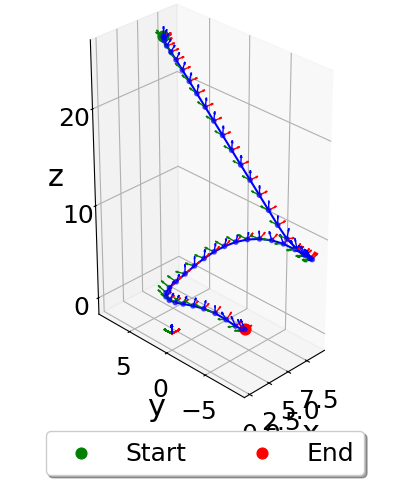

In [3]:
src_folder = os.path.join("resources", "paths")
drone_path = ds.Path(file=os.path.join(src_folder, "drone_path.csv"))
microphone_path = ds.Path(file=os.path.join(src_folder, "camera_path.csv"))
microphone_path.positions[:, 4] = 1.0   # qw
microphone_path.positions[:, 5:] = 0.0  # qx, qy, qz reset rotation of the microphone array
drone_sound = os.path.join("resources", "sounds", "flying_drone.wav")

fig = plt.figure(figsize=(15, 10))
ax = drone_path.plot_path_3d(show=False)
drone_path.plot_quaternion_directions(scale=1.0, show=False, ax=ax, legend=False)
microphone_path.plot_quaternion_directions(scale=1.0, show=False, ax=ax, legend=False)
ax.set_aspect('equal')
ax.view_init(elev=30, azim=225)
plt.tight_layout()
plt.savefig("_tmp/path_airsim.png", dpi=300)
plt.show()

mic_sample_rate = 8_000

# simulation environment
sim = ds.Simulation(
    temperature=20,
    pressure=1,
    relative_humidity=50
)

def circular_array(radius, num_mics):
    angles = np.linspace(0, 2 * np.pi, num_mics, endpoint=False)
    positions = np.zeros((num_mics, 7))
    positions[:, 0] = radius * np.cos(angles) # Set the x positions of the microphones
    positions[:, 1] = radius * np.sin(angles) # Set the y positions of the microphones
    positions[:, 4] = 1  # Set the quaternion w component to 1 (no rotation)
    return positions

# microphone
microphone = ds.microphones.MicrophoneArray(
    file_path="_tmp/simulation_drone.wav",
    positions=circular_array(radius=0.18, num_mics=32),
    sample_rate=mic_sample_rate
)
sim.add_microphone(path=microphone_path, microphone=microphone)

# source
source = ds.sources.AudioFile(filename=drone_sound, gain_db=10.0, loop=True)
sim.add_source(
    path=drone_path,
    source=source
)

# Simulation run

In [4]:
#sim.run()

# Simulation results visualization

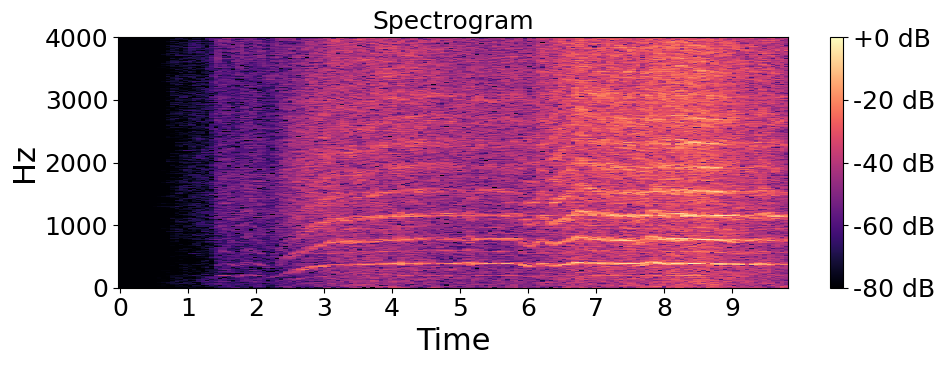

freq range [1093.75, 1218.75]


100%|██████████| 49/49 [00:15<00:00,  3.11it/s]


In [5]:

signal, sr = librosa.load("_tmp/simulation_drone.wav", sr=None, mono=False)

ipd.display(ipd.Audio(signal[0], rate=sr))

D = librosa.stft(signal[0])
S_db = librosa.amplitude_to_db(np.abs(D), ref=np.max)

plt.figure(figsize=(10, 4))
librosa.display.specshow(S_db, sr=sr, x_axis='time', y_axis='hz')
plt.colorbar(format='%+2.0f dB')
plt.title('Spectrogram')
plt.tight_layout()
#plt.ylim(1000, 406.25)
plt.show()



c = 343.0  # speed of sound
nfft = 256

freq_bins = range(35, 40)
freq_range = [(min(freq_bins)*sr)/nfft, (max(freq_bins)*sr)/nfft]  # FFT bins to use for estimation
print(f"freq range {freq_range}")

resolution_step = 1  # degrees
algo = pra.doa.normmusic.NormMUSIC(L=microphone.get_microphones().T, c=c, fs=sr, nfft=nfft,
                                azimuth=np.deg2rad(np.arange(-h_fov//2, h_fov//2, resolution_step)),
                                colatitude=np.deg2rad(np.arange(0, v_fov//1, resolution_step)),
                                dim=3, mode='far')

num_frames = 50
window_size = int(0.1*sr)
images = []
real_positions = []
predicted_positions = []

for image_frame in tqdm(range(frames.shape[0]-1)):
    start_sample = int(image_frame / framerate * mic_sample_rate)

    # Get the real position of the source relative to the microphone
    real_position_microphone, real_rotation_microphone = microphone_path.get_position(start_sample/sr)
    real_position_source, _ = drone_path.get_position(start_sample/sr)

    relative_position_azimuth = np.rad2deg(np.arctan2(real_position_source[1] - real_position_microphone[1], real_position_source[0] - real_position_microphone[0]))
    relative_position_colatitude = np.rad2deg(np.arccos((real_position_source[2] - real_position_microphone[2]) / np.linalg.norm(real_position_source - real_position_microphone)))

    real_positions.append((relative_position_azimuth, relative_position_colatitude))

    # Perform DOA estimation
    X = np.array(
        [pra.transform.stft.analysis(signal, nfft, nfft // 2).T for signal in signal[:, start_sample:start_sample+window_size]]
    )
    algo.locate_sources(X, freq_bins=freq_bins)

    predicted_positions.append((np.rad2deg(algo.azimuth_recon[0]), np.rad2deg(algo.colatitude_recon[0])))

    spatial_resp = algo.grid.values
    min_val = spatial_resp.min()
    max_val = spatial_resp.max()
    spatial_resp = (spatial_resp - min_val) / (max_val - min_val)
    images.append(spatial_resp.reshape((-1, h_fov//resolution_step)))

In [6]:

from matplotlib.colors import LinearSegmentedColormap
from matplotlib.colors import ListedColormap
from matplotlib.ticker import FuncFormatter

colormap = plt.get_cmap("viridis", 256)
colors = colormap(np.linspace(0, 1, 256)**0.8)
alpha = np.linspace(0, 1, 256)**0.8
colors[:, 3] = alpha
transparent_cm = ListedColormap(colors)

colormap = plt.get_cmap("hsv_r", 256)

colors = colormap(np.concatenate([np.linspace(0, 0.75, 56), np.linspace(0.75, 1, 100),  np.linspace(1, 1, 100)]))
alpha = np.linspace(0, 1, 256)
colors[:, 3] = alpha
transparent_cm = ListedColormap(colors)


fig, ax = plt.subplots()
img_rgb = ax.imshow(polar_images[0], extent=[extent_min_az, extent_max_az, extent_min_el, extent_max_el], animated=True)

vmax = max(np.max(im) for im in images)
img = ax.imshow(images[0], extent=[extent_max_az, extent_min_az, extent_min_el, extent_max_el], cmap=transparent_cm, vmin=0, vmax=vmax, alpha=0.5, animated=True)

img_real_all = ax.plot([pos[0] for pos in real_positions], [pos[1] for pos in real_positions], c='mistyrose', linestyle='dashed')
img_real = ax.scatter(real_positions[0][0], real_positions[0][1], c='red', marker='+', animated=True)
img_predicted = ax.scatter(predicted_positions[0][0], predicted_positions[0][1], c='blue', marker='x', animated=True)
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f'{x:.0f}°'))
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, pos: f'{x:.0f}°'))
ax.invert_xaxis()
fig.set_size_inches(8, 5)
ax.set_aspect(1)
plt.close()

def update(frame):
    img_rgb.set_array(polar_images[frame])
    img.set_array(images[frame])
    img_real.set_offsets([(real_positions[frame][0], real_positions[frame][1])])
    img_predicted.set_offsets([(predicted_positions[frame][0], predicted_positions[frame][1])])
    fig.savefig(f"_tmp/frame_{frame:04d}.png", dpi=300, bbox_inches='tight')
    return [img]

ani = FuncAnimation(fig, update, frames=len(images), interval=30000//num_frames, blit=True, repeat=True)
ani.save(filename="_tmp/tracking_airsim.mp4", writer="ffmpeg")

HTML(ani.to_jshtml())